# Student GPA Prediction Using Four Regression Models

## Objective
Compare four basic machine learning models for predicting GPA
from study-related information in a synthetic student dataset.

## Dataset
We use the Student Performance Dataset published on Kaggle:
https://www.kaggle.com/datasets/miadul/student-performance-dataset

The file contains 5,000 synthetic student records and 15 columns.
These are artificially generated records, not observations collected
from real students.

## Inputs and Target
The target variable is GPA.

The four selected input features are:
- StudyTimeWeekly
- Absences
- Tutoring
- ParentalSupport

StudentID is excluded because it is an identifier.
GradeClass is excluded because it reveals the GPA band and would
introduce target leakage.

## Models
1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. k-Nearest Neighbors Regressor

## Evaluation
We reserve 20% of the records for final testing and use five-fold
cross-validation on the remaining 80% for model development.

Model settings are selected using validation mean squared error.
We report RMSE and MAE, where lower values indicate smaller errors.
Feature scaling for k-NN is performed inside a pipeline.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("Libraries loaded successfully!")
print("Scikit-learn version:", sklearn.__version__)

Libraries loaded successfully!
Scikit-learn version: 1.9.0


In [2]:
#For creating the folders before saving any figures
from pathlib import Path

Path("results").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

In [3]:
students = pd.read_csv("synthetic_student_performance.csv")

students.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,1,3,16,13,0,2,0,0,0,0,3.158425,1
1,1002,18,1,2,0,17,28,0,2,1,1,1,0,2.794655,2
2,1003,15,1,0,1,13,18,1,4,0,0,0,1,3.774847,0
3,1004,17,1,0,3,6,4,0,3,1,0,0,0,3.040574,1
4,1005,17,0,1,2,6,20,0,4,0,0,0,0,3.382310,1


In [4]:
print("Number of rows:", students.shape[0])
print("Number of columns:", students.shape[1])
print("Missing values:", students.isna().sum().sum())
print("Duplicate rows:", students.duplicated().sum())

Number of rows: 5000
Number of columns: 15
Missing values: 0
Duplicate rows: 0


In [5]:
feature_columns = [
    "StudyTimeWeekly",
    "Absences",
    "Tutoring",
    "ParentalSupport"
]

X = students[feature_columns]
y = students["GPA"]

display(X.head())
display(y.head())

,StudyTimeWeekly,Absences,Tutoring,ParentalSupport
0,16,13,0,2
1,17,28,0,2
2,13,18,1,4
3,6,4,0,3
4,6,20,0,4


0    3.158425
1    2.794655
2    3.774847
3    3.040574
4    3.382310
Name: GPA, dtype: float64

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training inputs:", X_train.shape)
print("Test inputs:", X_test.shape)
print("Training GPAs:", y_train.shape)
print("Test GPAs:", y_test.shape)

Training inputs: (4000, 4)
Test inputs: (1000, 4)
Training GPAs: (4000,)
Test GPAs: (1000,)


In [7]:
# Join training inputs with their matching GPA answers
train_data = X_train.copy()
train_data["GPA"] = y_train

# Summarize the training data
display(train_data.describe().round(2))

,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,GPA
count,4000.00,4000.00,4000.00,4000.00,4000.00
mean,10.15,15.05,0.31,2.29,3.29
std,5.99,8.92,0.46,1.22,0.61
min,0.00,0.00,0.00,0.00,2.00
25%,5.00,7.00,0.00,2.00,2.82
50%,10.00,15.00,0.00,2.00,3.37
75%,15.00,23.00,1.00,3.00,3.89
max,20.00,30.00,1.00,4.00,4.00


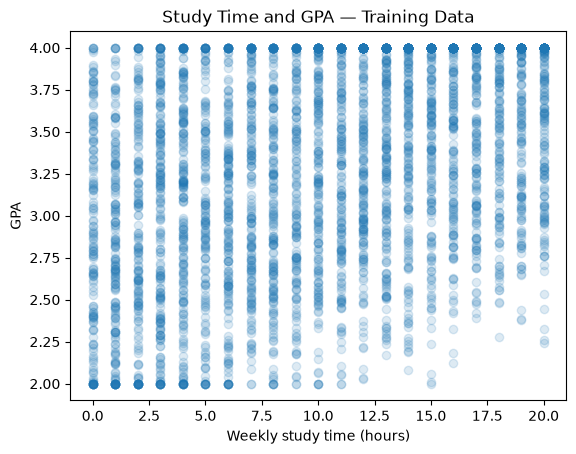

In [8]:
plt.scatter(
    train_data["StudyTimeWeekly"],
    train_data["GPA"],
    alpha=0.15
)

plt.xlabel("Weekly study time (hours)")
plt.ylabel("GPA")
plt.title("Study Time and GPA — Training Data")
plt.show()

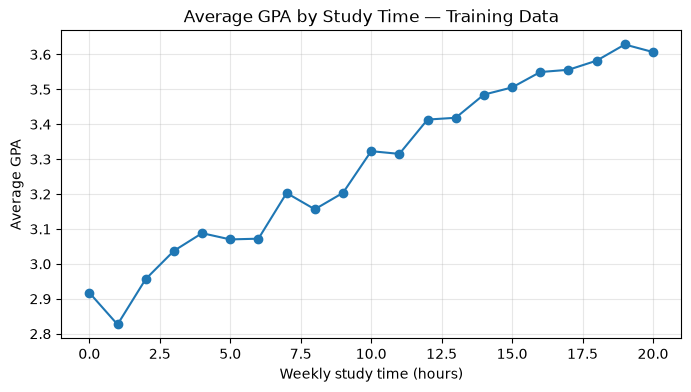

In [9]:
average_gpa = train_data.groupby("StudyTimeWeekly")["GPA"].mean()

average_gpa.plot(marker="o", figsize=(8, 4))

plt.xlabel("Weekly study time (hours)")
plt.ylabel("Average GPA")
plt.title("Average GPA by Study Time — Training Data")
plt.grid(alpha=0.3)
plt.show()

In [10]:
from sklearn.linear_model import LinearRegression

# Create the model
linear_model = LinearRegression()

# Learn from the training inputs and GPA answers
linear_model.fit(X_train, y_train)

print("Linear Regression model trained")

Linear Regression model trained


In [11]:
coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": linear_model.coef_
})

display(coefficients)
print("Intercept:", linear_model.intercept_)

,Feature,Coefficient
0,StudyTimeWeekly,0.038796
1,Absences,-0.022546
2,Tutoring,0.103014
3,ParentalSupport,0.080297


Intercept: 3.0180491165391836


In [12]:
from sklearn.model_selection import KFold, cross_val_score

# Reuse these same folds when comparing all four models
cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    linear_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

linear_mae_scores = -scores

print("MAE for each fold:", linear_mae_scores.round(3))
print("Average MAE:", round(linear_mae_scores.mean(), 3))

MAE for each fold: [0.446 0.444 0.436 0.428 0.442]
Average MAE: 0.439


In [13]:
from sklearn.dummy import DummyRegressor

baseline_model = DummyRegressor(strategy="mean")
baseline_scores = cross_val_score(
    baseline_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error"
)
baseline_mae_scores = -baseline_scores
comparison = pd.DataFrame({
    "Model": ["Average GPA baseline", "Linear Regression"],
    "Cross-validation MAE": [
        baseline_mae_scores.mean(),
        linear_mae_scores.mean()
    ]
})

display(comparison.round(3))

,Model,Cross-validation MAE
0,Average GPA baseline,0.523
1,Linear Regression,0.439


In [14]:
linear_mse_scores = cross_val_score(
    linear_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_squared_error"
)

# Convert negative MSE scores into RMSE for each fold
linear_rmse_scores = np.sqrt(-linear_mse_scores)

print("RMSE for each fold:", linear_rmse_scores.round(3))
print("Average RMSE:", round(linear_rmse_scores.mean(), 3))
print("Standard deviation:", round(linear_rmse_scores.std(), 3))

RMSE for each fold: [0.515 0.512 0.505 0.498 0.518]
Average RMSE: 0.51
Standard deviation: 0.007


# Decision tree regressor 


In [15]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

# Create and train the tree
tree_model = DecisionTreeRegressor(random_state=42)
tree_model.fit(X_train, y_train)

# Check its error on the students it learned from
tree_train_predictions = tree_model.predict(X_train)

tree_train_rmse = np.sqrt(
    mean_squared_error(y_train, tree_train_predictions)
)

# Evaluate using the same five validation folds
tree_mse_scores = cross_val_score(
    tree_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_squared_error"
)

tree_rmse_scores = np.sqrt(-tree_mse_scores)

print("Training RMSE:", round(tree_train_rmse, 3))
print("Validation RMSE for each fold:", tree_rmse_scores.round(3))
print("Average validation RMSE:", round(tree_rmse_scores.mean(), 3))
print("Validation RMSE standard deviation:", round(tree_rmse_scores.std(), 3))


Training RMSE: 0.284
Validation RMSE for each fold: [0.719 0.692 0.703 0.697 0.693]
Average validation RMSE: 0.701
Validation RMSE standard deviation: 0.01


In [16]:
# Limit the tree to a maximum of three splits along any path
shallow_tree_model = DecisionTreeRegressor(
    max_depth=3,
    random_state=42
)

shallow_tree_model.fit(X_train, y_train)

shallow_train_predictions = shallow_tree_model.predict(X_train)

shallow_train_rmse = np.sqrt(
    mean_squared_error(y_train, shallow_train_predictions)
)

shallow_mse_scores = cross_val_score(
    shallow_tree_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_squared_error"
)

shallow_rmse_scores = np.sqrt(-shallow_mse_scores)

print("Training RMSE:", round(shallow_train_rmse, 3))
print("Average validation RMSE:", round(shallow_rmse_scores.mean(), 3))
print("Validation RMSE standard deviation:",
      round(shallow_rmse_scores.std(), 3))

Training RMSE: 0.528
Average validation RMSE: 0.537
Validation RMSE standard deviation: 0.008


In [17]:
from sklearn.model_selection import GridSearchCV

tree_grid_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid={"max_depth": [2, 3, 4, 5, 6]},
    scoring="neg_mean_squared_error",
    cv=cv
)

tree_grid_search.fit(X_train, y_train)

# GridSearchCV refits the selected model on all training data
best_tree_model = tree_grid_search.best_estimator_


In [18]:
print("Selected settings:", tree_grid_search.best_params_)
print(
    "Validation RMSE (root of mean fold MSE):",
    round(np.sqrt(-tree_grid_search.best_score_), 3)
)

Selected settings: {'max_depth': 5}
Validation RMSE (root of mean fold MSE): 0.527


# Model 3:- Random Forest Regression

In [19]:
from sklearn.ensemble import RandomForestRegressor

forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

forest_model.fit(X_train, y_train)

forest_train_predictions = forest_model.predict(X_train)

forest_train_rmse = np.sqrt(
    mean_squared_error(y_train, forest_train_predictions)
)

forest_mse_scores = cross_val_score(
    forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_squared_error"
)

forest_rmse_scores = np.sqrt(-forest_mse_scores)

print("Training RMSE:", round(forest_train_rmse, 3))
print("Average validation RMSE:", round(forest_rmse_scores.mean(), 3))
print(
    "Validation RMSE standard deviation:",
    round(forest_rmse_scores.std(), 3)
)

Training RMSE: 0.32
Average validation RMSE: 0.579
Validation RMSE standard deviation: 0.008


In [20]:
forest_grid_search = GridSearchCV(
    estimator=RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    param_grid={
        "max_depth": [3, 5, 8],
        "min_samples_leaf": [5, 20]
    },
    scoring="neg_mean_squared_error",
    cv=cv
)

forest_grid_search.fit(X_train, y_train)

best_forest_model = forest_grid_search.best_estimator_

print("Selected settings:", forest_grid_search.best_params_)
print(
    "Validation RMSE (root of mean fold MSE):",
    round(np.sqrt(-forest_grid_search.best_score_), 3)
)

Selected settings: {'max_depth': 5, 'min_samples_leaf': 20}
Validation RMSE (root of mean fold MSE): 0.515


# KNN Model 

In [21]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor(n_neighbors=5))
])

knn_model.fit(X_train, y_train)

knn_train_predictions = knn_model.predict(X_train)

knn_train_rmse = np.sqrt(
    mean_squared_error(y_train, knn_train_predictions)
)

knn_mse_scores = cross_val_score(
    knn_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_squared_error"
)

knn_rmse_scores = np.sqrt(-knn_mse_scores)

print("Training RMSE:", round(knn_train_rmse, 3))
print("Average validation RMSE:", round(knn_rmse_scores.mean(), 3))
print(
    "Validation RMSE standard deviation:",
    round(knn_rmse_scores.std(), 3)
)

Training RMSE: 0.455
Average validation RMSE: 0.562
Validation RMSE standard deviation: 0.009


In [22]:
knn_grid_search = GridSearchCV(
    estimator=knn_model,
    param_grid={
        "knn__n_neighbors": [5, 10, 20, 40, 80]
    },
    scoring="neg_mean_squared_error",
    cv=cv
)

knn_grid_search.fit(X_train, y_train)

best_knn_model = knn_grid_search.best_estimator_

print("Selected settings:", knn_grid_search.best_params_)
print(
    "Validation RMSE (root of mean fold MSE):",
    round(np.sqrt(-knn_grid_search.best_score_), 3)
)

Selected settings: {'knn__n_neighbors': 80}
Validation RMSE (root of mean fold MSE): 0.515


Since k-NN selected 80, the largest value we tried, one small extension to check larger neighborhoods then evaluating the models on the untouched test set.

In [23]:
knn_grid_search = GridSearchCV(
    estimator=knn_model,
    param_grid={
        "knn__n_neighbors": [40, 80, 120, 160, 240]
    },
    scoring="neg_mean_squared_error",
    cv=cv
)

knn_grid_search.fit(X_train, y_train)

best_knn_model = knn_grid_search.best_estimator_

print("Selected settings:", knn_grid_search.best_params_)
print(
    "Validation RMSE (root of mean fold MSE):",
    round(np.sqrt(-knn_grid_search.best_score_), 4)
)

Selected settings: {'knn__n_neighbors': 120}
Validation RMSE (root of mean fold MSE): 0.5138


Comparing all four models using the same RMSE calculation taking square root of the average fold MSE for each model.

In [24]:
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "k-NN"
    ],
    "Validation RMSE": [
        np.sqrt(-linear_mse_scores.mean()),
        np.sqrt(-tree_grid_search.best_score_),
        np.sqrt(-forest_grid_search.best_score_),
        np.sqrt(-knn_grid_search.best_score_)
    ],
    "Settings": [
        "Default",
        str(tree_grid_search.best_params_),
        str(forest_grid_search.best_params_),
        str(knn_grid_search.best_params_)
    ]
})

model_comparison = model_comparison.sort_values(
    "Validation RMSE"
).reset_index(drop=True)

display(model_comparison.round(4))

,Model,Validation RMSE,Settings
0,Linear Regression,0.5096,Default
1,k-NN,0.5138,{'knn__n_neighbors': 120}
2,Random Forest,0.5145,"{'max_depth': 5, 'min_samples_leaf': 20}"
3,Decision Tree,0.5269,{'max_depth': 5}


Freezing all model settings and evaluating them on the 1000 test students we kept aside. 
We won’t change settings based on these test results.

In [25]:
from sklearn.metrics import mean_absolute_error

final_models = {
    "Linear Regression": linear_model,
    "Decision Tree": best_tree_model,
    "Random Forest": best_forest_model,
    "k-NN": best_knn_model
}

# Selected using validation results, before inspecting test results
selected_model_name = "Linear Regression"

test_results = []
test_predictions = {}

for name, model in final_models.items():
    predictions = model.predict(X_test)
    test_predictions[name] = predictions

    test_results.append({
        "Model": name,
        "Test MAE": mean_absolute_error(y_test, predictions),
        "Test RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        )
    })

test_comparison = pd.DataFrame(test_results)

display(test_comparison.round(4))

,Model,Test MAE,Test RMSE
0,Linear Regression,0.4424,0.5106
1,Decision Tree,0.4585,0.5293
2,Random Forest,0.4485,0.5151
3,k-NN,0.4480,0.5133


The differences between models are small, so our conclusion should be modest.
Linear Regression performed best in this experiment; greater complexity did not improve prediction.

The main model comparison is complete. 
Next is inspecting the selected model’s predictions visually.

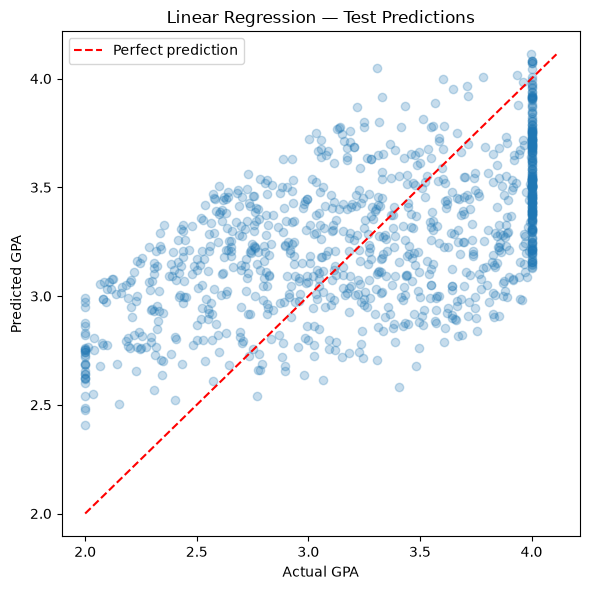

In [26]:
predictions = test_predictions[selected_model_name]

plt.figure(figsize=(6, 6))
plt.scatter(y_test, predictions, alpha=0.25)

lower = min(y_test.min(), predictions.min())
upper = max(y_test.max(), predictions.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual GPA")
plt.ylabel("Predicted GPA")
plt.title("Linear Regression — Test Predictions")
plt.legend()
plt.tight_layout()
plt.savefig(
   "figures/linear_regression_predictions.png",
  dpi=300,
 bbox_inches="tight"
)
plt.show()

create a simple comparison figure for the report

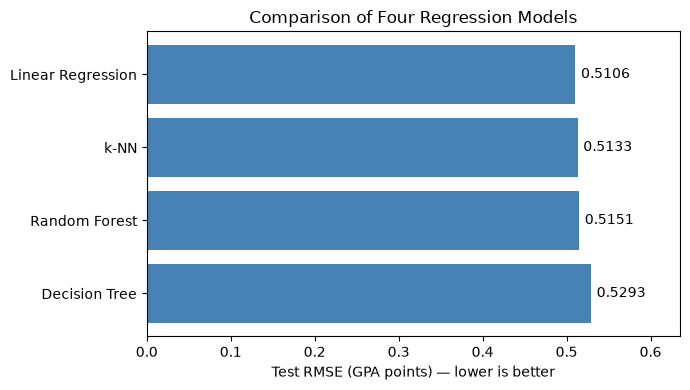

In [27]:
plot_data = test_comparison.sort_values("Test RMSE")

plt.figure(figsize=(7, 4))

bars = plt.barh(
    plot_data["Model"],
    plot_data["Test RMSE"],
    color="steelblue"
)

plt.bar_label(bars, fmt="%.4f", padding=4)
plt.xlabel("Test RMSE (GPA points) — lower is better")
plt.title("Comparison of Four Regression Models")
plt.xlim(0, plot_data["Test RMSE"].max() * 1.2)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(
    "figures/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [28]:
from pathlib import Path

Path("results").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

model_comparison.to_csv(
    "results/validation_comparison.csv",
    index=False
)

test_comparison.to_csv(
    "results/test_comparison.csv",
    index=False
)

print("Result tables saved")

Result tables saved


# Conclusion
Linear Regression achieved the lowest test RMSE (0.5106) and MAE
(0.4424) among the four models. Differences between the models
were very small.

Limiting tree complexity reduced overfitting. Scaling was included
inside the k-NN pipeline to prevent leakage during cross-validation.

The selected Linear Regression model often overestimated low GPAs
and underestimated high GPAs. Its predictions were not constrained
to the GPA range.

These results apply to this synthetic dataset and four selected
inputs; performance on real student data has not been established.